# 04 — Benzer Şarkı Bulucu

Bir şarkı veriyoruz, ses olarak ona en çok benzeyen şarkıları buluyoruz. Bu, içerik tabanlı (content-based) bir öneri sistemi:

- Her şarkı 9 ses özelliğiyle 9 boyutlu bir uzayda bir nokta.
- Özellikler ölçekleniyor (ortalama 0, standart sapma 1).
- İki şarkının benzerliği bu uzaydaki **Öklid uzaklığı** ile ölçülüyor. Uzaklık küçüldükçe benzerlik artıyor.

Bulucu `src/oneri.py` içinde. Aynı kod Streamlit demosunda (`app.py`) da kullanılıyor.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.neighbors import NearestNeighbors

sys.path.append(str(Path.cwd().parent))
from src.oneri import BenzerSarkiBulucu
from src.ozellikler import surumleri_birlestir
from src.veri import SES_OZELLIKLERI, temizle, tekil_sarkilar, veri_yukle

FIGURLER = Path.cwd().parent / "figures"
RASTGELE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Veri

Hit notebook'undaki gibi aynı şarkının farklı sürümlerini birleştiriyoruz. Yoksa bir şarkıya en benzer şarkı olarak, kendisinin derleme albümdeki kopyası önerilirdi.

In [2]:
sarkilar = surumleri_birlestir(tekil_sarkilar(temizle(veri_yukle())))
bulucu = BenzerSarkiBulucu(sarkilar)
print(f"{len(sarkilar):,} şarkı arasında arama yapılıyor")

81,056 şarkı arasında arama yapılıyor


## 2. Kullanım

In [3]:
bulucu.ara("bohemian")[["track_name", "artists", "track_genre", "popularity"]]

,track_name,artists,track_genre,popularity
388,Bohemian Rhapsody - Remastered 2011,Queen,rock,82
1444,Bohemian Rhapsody,Queen,rock,75
16828,Bohemian Rhapsody - Acoustic,John Adams,acoustic,52
25381,Bohemian Sunset,Jazzanova,trip-hop,46
25865,Bohemian Rhapsody (Glee Cast Version) (feat. J...,Glee Cast;Jonathan Groff,club,45
57961,Bohemian Rhapsody,Hayseed Dixie,bluegrass,22


In [4]:
GOSTER = ["track_name", "artists", "track_genre", "popularity", "uzaklik"]

def oner(sorgu, n=8, min_populerlik=40):
    """Arama metnine uyan en popüler şarkıyı bulur ve benzerlerini listeler."""
    sarki = bulucu.ara(sorgu).iloc[0]
    print(f"🎵 {sarki['track_name']} — {sarki['artists']} ({sarki['track_genre']})")
    return bulucu.benzerler(sarki["track_id"], n=n, min_populerlik=min_populerlik)[GOSTER].round(2)

oner("Bohemian Rhapsody")

🎵 Bohemian Rhapsody - Remastered 2011 — Queen (rock)


,track_name,artists,track_genre,popularity,uzaklik
31583,The Passion (Live Acoustic) - Bonus,Hillsong Worship;Brooke Ligertwood,world-music,42,0.39
26901,Sevsen Ne Olurdu,Gülden Karaböcek,turkish,45,0.74
29352,Mere Yaar,The Local Train,indian,43,0.75
22310,Goodbye Milky Way,Enigma,new-age,48,0.86
26215,Mera Yaar Meri Daulat,Goldie Khristi,indian,45,0.87
16978,Melt My Heart To Stone,Adele,british,52,0.88
20249,Behold (Then Sings My Soul),Hillsong Worship,world-music,50,0.92
3419,Collide (Sped Up Remix),Justine Skye;Tyga,alternative,68,0.92


In [5]:
oner("Smells Like Teen Spirit")

🎵 Smells Like Teen Spirit — Nirvana (alt-rock)


,track_name,artists,track_genre,popularity,uzaklik
7973,She's Thunderstorms,Arctic Monkeys,garage,61,0.41
5129,Cemetery Drive,My Chemical Romance,emo,65,0.42
1435,Buddy Holly,Weezer,power-pop,75,0.43
29036,Corazon De Un Cuento Roto,PXNDX,emo,43,0.45
4069,Break,Three Days Grace,grunge,67,0.50
12762,There For You,Gorgon City;MK,deep-house,56,0.50
1059,Hail to the King,Avenged Sevenfold,alternative,76,0.51
5804,No Excuses,Alice In Chains,grunge,64,0.51


In [6]:
oner("Blinding Lights")

🎵 Blinding Lights — The Weeknd (pop)


,track_name,artists,track_genre,popularity,uzaklik
9878,Viah,Jass Manak,hip-hop,59,0.29
17206,Thinkin About,ShockOne;Lee Mvtthews,drum-and-bass,52,0.33
28858,BODY,LICK;LUNA AURA,club,43,0.38
15017,Broken,Netsky;Montell2099,drum-and-bass,54,0.38
4304,30/90,Andrew Garfield;Joshua Henry;Vanessa Hudgens;R...,show-tunes,67,0.43
29907,Shooting Star,Nam Woo-hyun,singer-songwriter,43,0.44
11049,Danger Line,Avenged Sevenfold,metal,58,0.46
18978,The Mother We Share,CHVRCHES,synth-pop,51,0.48


In [7]:
oner("Şımarık")

🎵 Şımarık — Tarkan (turkish)


,track_name,artists,track_genre,popularity,uzaklik
10944,Adhiya,Karan Aujla,hip-hop,58,0.45
8059,Don't Sweat The Technique,Eric B. & Rakim,hardcore,61,0.52
30058,Bardak Taşıyor,Can Bonomo,turkish,43,0.62
26963,Duas Cidades,BaianaSystem,afrobeat,44,0.64
7485,Red Chilli,Diljit Dosanjh,pop-film,62,0.65
30039,Yıkılıyorum (feat. Şehinşah & Ceg),Artz;Şehinşah;Ceg,turkish,43,0.70
3570,Only God Can Judge Me (ft. Rappin' 4-Tay),2Pac;Rappin' 4-Tay,funk,68,0.74
29363,It's Rocking,Pritam;Alisha Chinai,indian,43,0.76


In [8]:
oner("Seni Dert Etmeler")

🎵 Seni Dert Etmeler — Madrigal (turkish)


,track_name,artists,track_genre,popularity,uzaklik
23672,Oya,Grupo Sensação,pagode,47,0.62
32741,¡Lobo ¿Estás?!,Patricio Rey y sus Redonditos de Ricota,punk,41,0.73
5817,"Touch, Peel And Stand",Days Of The New,grunge,64,0.75
34059,Quase Nada,Zeca Baleiro,mpb,40,0.75
23685,Seja Mais Você,Grupo Raça,pagode,47,0.76
34542,Bak Şu Adama Aşık Oldu,Ayla Algan,turkish,40,0.84
2466,Ramble On - 1990 Remaster,Led Zeppelin,hard-rock,71,0.86
29686,Velocidade da Luz / Temporal / Juventude - Ao ...,Quinteto S.A.,pagode,43,0.87


**Gözlem:**
- **Öneri kalitesi şarkıya göre değişiyor.** Smells Like Teen Spirit için sonuçlar çok iyi: Arctic Monkeys, Weezer, My Chemical Romance, Alice In Chains. Bohemian Rhapsody için ise zayıf. Bölümlerden oluşan, baladdan operaya ve rock'a geçen bir şarkı, tek bir ortalama değerle iyi özetlenemiyor.
- Öneriler ses olarak gerçekten yakın ama çoğu zaman **farklı türlerden** geliyor. Şımarık'ın komşuları arasında Hint pop'u, hip-hop ve Brezilya müziği var. Bu iki şekilde okunabilir:
- **Artısı:** Tür sınırlarını aşan keşifler. "Bu Türk pop şarkısını sevdiysen, şu Pencap şarkısını da sevebilirsin."
- **Sınırlılığı:** Dil, kültür ve sözler hesaba katılmıyor. Gerçek öneri sistemleri bu yüzden ses özelliklerini dinleme geçmişiyle birleştirir (collaborative filtering).

## 3. Neden benziyorlar? Profil karşılaştırması

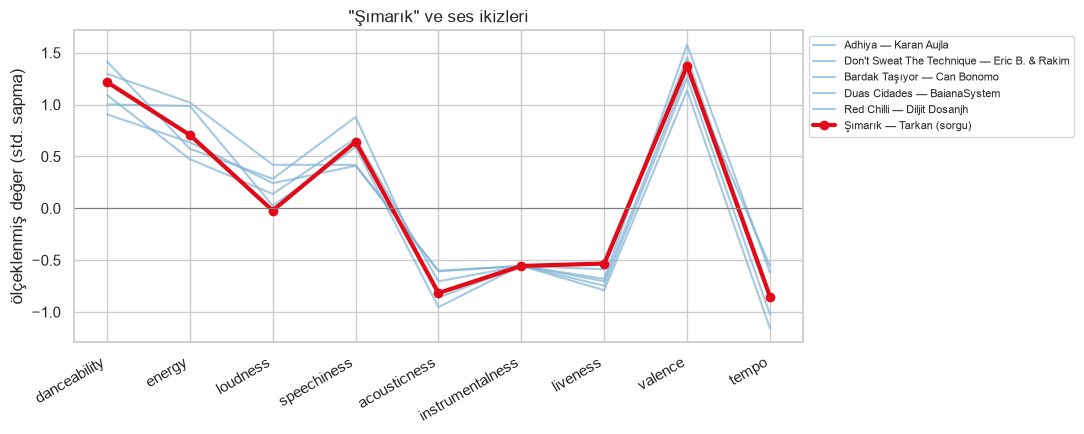

In [9]:
def profil_ciz(sorgu, n=5, dosya=None):
    sarki = bulucu.ara(sorgu).iloc[0]
    komsular = bulucu.benzerler(sarki["track_id"], n=n, min_populerlik=40)
    i = bulucu._konum[sarki["track_id"]]
    j = [bulucu._konum[t] for t in komsular["track_id"]]

    fig, eksen = plt.subplots(figsize=(11, 4.5))
    x = np.arange(len(SES_OZELLIKLERI))
    for k, (_, s) in zip(j, komsular.iterrows()):
        eksen.plot(x, bulucu.X[k], color="#7FB3D5", alpha=0.7, lw=1.5,
                   label=f"{s['track_name'][:25]} — {s['artists'][:18]}")
    eksen.plot(x, bulucu.X[i], color="#E30A17", lw=3, marker="o",
               label=f"{sarki['track_name']} — {sarki['artists']} (sorgu)")
    eksen.axhline(0, color="gray", lw=0.8)
    eksen.set_xticks(x, SES_OZELLIKLERI, rotation=30, ha="right")
    eksen.set_ylabel("ölçeklenmiş değer (std. sapma)")
    eksen.set_title(f"\"{sarki['track_name']}\" ve ses ikizleri")
    eksen.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    if dosya:
        fig.savefig(FIGURLER / dosya, dpi=120, bbox_inches="tight")
    plt.show()

profil_ciz("Şımarık", dosya="04_simarik_ikizleri.png")

Kırmızı çizgi sorgu şarkısı, mavi çizgiler en yakın 5 komşusu. Komşular 9 özelliğin hepsinde sorgu şarkısının profilini yakından takip ediyor.

## 4. Bulucu ne kadar iyi?

Bir öneri sistemini değerlendirmenin en iyi yolu gerçek kullanıcı tepkisidir (tıklama, dinleme). Bizde bu veri yok. Bunun yerine bir **vekil ölçüt** kullanıyoruz: **Bir şarkının en yakın 10 komşusunun kaçı onunla aynı türde?**

Bu ölçüt kusurlu: Tür etiketleri gürültülü, türlerin yarısı ses olarak tutarsız (bkz. kümeleme notebook'u) ve birden fazla türde geçen şarkılarda yalnızca bir tür etiketi tutuluyor. Ama farklı yöntemleri birbiriyle ve rastgele seçimle karşılaştırmak için yeterli.

In [10]:
rng = np.random.default_rng(RASTGELE)
orneklem = rng.choice(len(sarkilar), 3000, replace=False)
turler = sarkilar["track_genre"].to_numpy()

def tur_uyumu(X, metrik="euclidean", k=10):
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metrik).fit(X)
    _, komsu = nn.kneighbors(X[orneklem])
    komsu = komsu[:, 1:]  # ilk komşu şarkının kendisi
    return (turler[komsu] == turler[orneklem][:, None]).mean(axis=1)

ham = sarkilar[SES_OZELLIKLERI].to_numpy()
degerlendirme = pd.Series({
    "Rastgele 10 şarkı": (turler[rng.choice(len(turler), (3000, 10))] == turler[orneklem][:, None]).mean(),
    "Ölçeklemeden (ham özellikler)": tur_uyumu(ham).mean(),
    "Ölçekli + Öklid (bizim bulucu)": tur_uyumu(bulucu.X).mean(),
    "Ölçekli + kosinüs": tur_uyumu(bulucu.X, "cosine").mean(),
}, name="aynı türden komşu oranı")
(degerlendirme * 100).round(1)

Rastgele 10 şarkı                  1.0
Ölçeklemeden (ham özellikler)      6.8
Ölçekli + Öklid (bizim bulucu)    11.5
Ölçekli + kosinüs                 11.4
Name: aynı türden komşu oranı, dtype: float64

**Yorum:**
- Bulucunun önerdiği şarkılar, rastgele seçime göre yaklaşık **10 kat** daha sık aynı türden.
- **Ölçekleme şart:** Ham özelliklerde tempo (50–200) ve loudness (−50–0) uzaklığa hâkim oluyor, uyum neredeyse yarıya düşüyor.
- Öklid ve kosinüs uzaklığı neredeyse aynı sonucu veriyor. Daha basit ve anlaşılır olduğu için Öklid uzaklığında kalıyoruz.

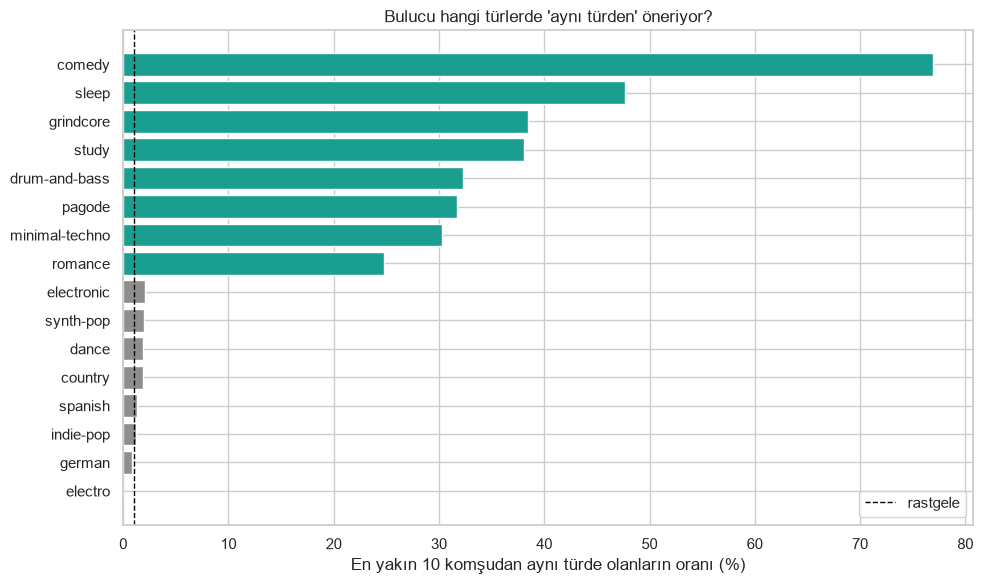

In [11]:
uyum = pd.Series(tur_uyumu(bulucu.X), index=turler[orneklem]).groupby(level=0).mean()
uyum = uyum[pd.Series(turler[orneklem]).value_counts().reindex(uyum.index) >= 15]  # en az 15 örneği olan türler

fig, eksen = plt.subplots(figsize=(10, 6))
secim = pd.concat([uyum.nsmallest(8).sort_values(), uyum.nlargest(8).sort_values()])
eksen.barh(secim.index, secim.values * 100, color=["#8E8E8E"] * 8 + ["#1A9E8F"] * 8)
eksen.axvline(degerlendirme["Rastgele 10 şarkı"] * 100, ls="--", color="black", lw=1, label="rastgele")
eksen.set_xlabel("En yakın 10 komşudan aynı türde olanların oranı (%)")
eksen.set_title("Bulucu hangi türlerde 'aynı türden' öneriyor?")
eksen.legend()
fig.tight_layout()
fig.savefig(FIGURLER / "04_tur_uyumu.png", dpi=120)
plt.show()

**Yorum:**
- **Uyumun en yüksek olduğu türler** çok belirgin bir ses kalıbına sahip: comedy (konuşma), sleep, grindcore, study, drum-and-bass.
- **Uyumun en düşük olduğu türler** (electro, dance, electronic, synth-pop) birbirine çok benzeyen **kardeş türler**. Komşular yine elektronik dans müziği, ama "electro" yerine "edm" ya da "house" etiketli. Yani buradaki düşük uyum her zaman kötü öneri anlamına gelmiyor. Vekil ölçütün sınırı burada görünüyor.
- German, spanish ve country gibi kökenle tanımlanan türlerde de uyum rastgele düzeyinde. Bu, kümeleme notebook'undaki bulguyla tutarlı.

## 5. Türk müziğinin ses ikizleri

Her Türk şarkısı için, **Türk olmayan** şarkılar arasındaki en yakın 10 komşuya bakıyoruz. Sonra bu komşuların hangi türlerden geldiğini sayıyoruz. Yani "Türk müziği, ses olarak dünyada en çok hangi müziklere benziyor?" sorusunu soruyoruz.

In [12]:
turk = (sarkilar["track_genre"] == "turkish").to_numpy()
nn = NearestNeighbors(n_neighbors=10).fit(bulucu.X[~turk])
_, komsu = nn.kneighbors(bulucu.X[turk])
komsu_turleri = pd.Series(turler[~turk][komsu.ravel()])

# Beklenen: türlerin Türk olmayan şarkılardaki payı (rastgele komşu seçilseydi)
beklenen = pd.Series(turler[~turk]).value_counts(normalize=True)
gozlenen = komsu_turleri.value_counts(normalize=True)
# Çok az komşusu olan türlerde oran gürültülü olur; en az 50 komşusu olanlara bakıyoruz
yeterli = komsu_turleri.value_counts() >= 50
oran = (gozlenen / beklenen)[yeterli].dropna().sort_values(ascending=False)

print(f"{turk.sum()} Türk şarkısı × 10 komşu = {len(komsu_turleri):,} komşu")
pd.DataFrame({"komşuların %'si": (gozlenen * 100).round(1),
              "beklenenin kaç katı": oran.round(2)}).loc[oran.index[:12]]

849 Türk şarkısı × 10 komşu = 8,490 komşu


,komşuların %'si,beklenenin kaç katı
french,2.7,2.54
dancehall,2.6,2.46
hip-hop,2.0,2.44
sad,1.6,2.38
latino,1.1,2.33
j-dance,2.1,2.25
alternative,0.6,2.19
malay,2.6,2.19
emo,2.2,2.08
soul,0.7,1.98


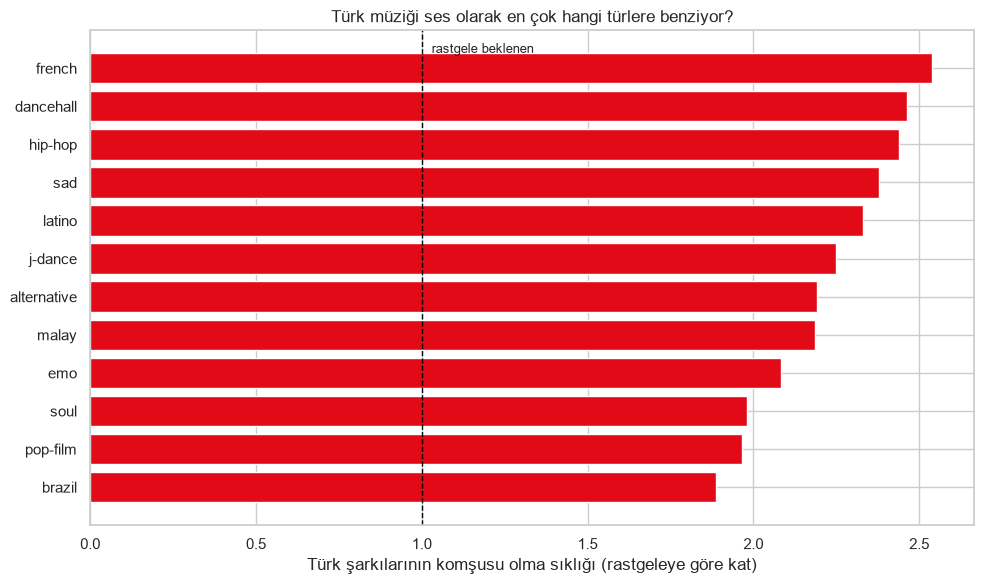

In [13]:
fig, eksen = plt.subplots(figsize=(10, 6))
ust = oran.head(12).sort_values()
eksen.barh(ust.index, ust.values, color="#E30A17")
eksen.axvline(1, ls="--", color="black", lw=1)
eksen.text(1.03, len(ust) - 0.6, "rastgele beklenen", fontsize=9)
eksen.set_xlabel("Türk şarkılarının komşusu olma sıklığı (rastgeleye göre kat)")
eksen.set_title("Türk müziği ses olarak en çok hangi türlere benziyor?")
fig.tight_layout()
fig.savefig(FIGURLER / "04_turk_ses_ikizleri.png", dpi=120)
plt.show()

In [14]:
# En az benzenen türler (hiç ya da çok az komşu çıkan türler dahil)
(gozlenen.reindex(beklenen.index, fill_value=0) / beklenen).sort_values().head(8).round(2)

sleep             0.01
grindcore         0.02
death-metal       0.16
black-metal       0.18
iranian           0.21
metalcore         0.24
detroit-techno    0.26
idm               0.27
Name: proportion, dtype: float64

In [15]:
# En popüler Türk şarkılarının yabancı ses ikizleri
populer_turk = sarkilar[turk].nlargest(8, "popularity")
satirlar = []
for _, s in populer_turk.iterrows():
    ikiz = bulucu.benzerler(s["track_id"], n=50, min_populerlik=40)
    ikiz = ikiz[ikiz["track_genre"] != "turkish"].iloc[0]
    satirlar.append({"Türk şarkısı": f"{s['track_name']} — {s['artists']}",
                     "yabancı ses ikizi": f"{ikiz['track_name']} — {ikiz['artists']}",
                     "ikizin türü": ikiz["track_genre"], "uzaklık": round(ikiz["uzaklik"], 2)})
pd.DataFrame(satirlar)

,Türk şarkısı,yabancı ses ikizi,ikizin türü,uzaklık
0,Seni Dert Etmeler — Madrigal,Oya — Grupo Sensação,pagode,0.62
1,M. — Anıl Emre Daldal,Red Wine at Dawn — Blackburri,study,0.73
2,Arıyorum — EDIS,Gravity (feat. Satoshi Fujihara) [OFFICIAL HIG...,emo,0.34
3,Martılar — EDIS,死神 — Kenshi Yonezu,anime,0.43
4,Nerdesin — Ezhel,Condo — Afro B;T-Pain,dancehall,0.52
5,La Câlin — Serhat Durmus,Loneliness — Kato,anime,0.65
6,Krvn — UZI,Ve Svym Stavu — Schyzo;RNZ,emo,0.73
7,Şımarık — Tarkan,Adhiya — Karan Aujla,hip-hop,0.45


**Yorum:** Türk müziği ses olarak en çok **Fransız müziği, dancehall, hip-hop, "sad" çalma listeleri ve latino** ile örtüşüyor. Her biri rastgele beklenenden 2.3–2.5 kat daha sık komşu çıkıyor. Bu da kümelemedeki "dans/parti + duygusal" ikiliğiyle tutarlı.

En az benzediği türler metal, techno, uyku ve ilginç biçimde **İran müziği** (beklenenin 0.21 katı). Coğrafi yakınlığa rağmen, bu veri setindeki İran şarkıları en düşük mutluluk ve dans edilebilirlik değerlerine sahip yavaş parçalar. Türk şarkıları ise ortalamadan daha dans edilebilir.

## 6. Özet

- **Bulucu çalışıyor:** 81 bin şarkı arasında bir sorgu ~0.1 saniye sürüyor. Önerilen şarkılar rastgele seçime göre **~10 kat** daha sık aynı türden (%11.5'e karşı %1.0).
- **Ölçekleme kritik:** Ölçeklemeden tür uyumu %6.8'e düşüyor. Öklid ve kosinüs uzaklığı arasında fark yok.
- **Güçlü yanı:** Tür sınırlarını aşan keşifler. Smells Like Teen Spirit gibi net bir ses karakteri olan şarkılarda öneriler çok isabetli.
- **Zayıf yanı:** Dil, kültür, söz ve şarkının zaman içindeki değişimi hesaba katılmıyor. Bohemian Rhapsody gibi bölümlü şarkılarda ortalama özellikler yetersiz kalıyor.
- **Türk müziğinin ses ikizleri:** Fransız müziği, dancehall, hip-hop, "sad" ve latino. En uzak olduğu türler uyku müziği, grindcore, death/black metal ve İran müziği.

**Demo:** Bu bulucu `app.py` ile tarayıcıda çalışan bir demoya dönüştürüldü; testleri `tests/` altında.